# Montra Hospitality Intel — Guest Experience Analytics

**Author:** Marc Aurel Ntjam Minkeng

Montra Hospitality Intel helps independent and mid-sized UK hotels turn operational data into business intelligence. Its platform already reports structured metrics (revenue, occupancy, bookings). This project extends it into **customer experience intelligence**: turning free-text guest reviews into evidence of *what* guests talk about, *how* they feel about it, and *where* hotels should act.

## Business problem

Ratings tell a hotel **how** satisfied guests are, but not **why**. The reasons sit in the review text, which today is read by hand. That is slow, inconsistent, and recurring problems stay hidden, especially because one review often mixes praise and complaints about different parts of a stay.

## What this notebook covers

| Phase | What happens | Output |
|---|---|---|
| 1. Business understanding | Turn the business questions into things we can measure | Key questions and success criteria |
| 2. Data collection | Connect to the database, extract the four tables, take a first look, join them into one table | Raw CSV files and one combined table |
| 3. Data cleaning and preparation | Fix missing values, duplicates, data types, inconsistent names; clean the review text; validate the result | `reviews_clean.csv` and `nlp_corpus.csv` |
| 4. Exploratory data analysis (EDA) | Explore the cleaned data: sentiment, ratings, time, text, hotels, guests, bookings | Findings that guide the modelling phases |

Each code cell has a short **"What this code does"** note above it and an **Insight** below it that explains what the output shows.

---
# Phase 1 — Business Understanding

The project brief asks five key questions. This table translates each one into something measurable. This notebook starts answering the first one; the others are answered in the later modelling phases (topic modelling and sentiment classification).

| Key question | What we measure |
|---|---|
| What factors influence guest satisfaction? | How rating and sentiment change with hotel, guest and booking characteristics |
| What issues repeatedly appear in guest feedback? | The topics guests mention most often in negative reviews |
| Which topics generate positive or negative sentiment? | The share of positive, neutral and negative mentions for each topic |
| How can management spot recurring problems? | A repeatable pipeline whose outputs are linked to each review by `review_id` |
| Which model classifies sentiment best? | Accuracy, precision, recall and F1 on a held-out test set |

**Success criteria for Phases 2–4:** every review can be linked to its booking, guest and hotel; the cleaned data passes all validation checks; and the EDA tells us what to expect before modelling.

## Setup

**What this code does:**
- Imports the libraries used in this notebook: **pandas** and **numpy** for tables and numbers, **matplotlib** and **seaborn** for charts, **sqlalchemy** and **dotenv** for the database connection.
- Defines the project folders (`data/raw` for extracted tables, `data/processed` for cleaned outputs).
- Sets the chart style and the three sentiment colours used in every chart (red = negative, grey = neutral, blue = positive).

In [46]:
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Project folders: this notebook lives in Project_montra/notebook
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROC_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROC_DIR.mkdir(parents=True, exist_ok=True)

# Chart style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
SENT_ORDER = ["negative", "neutral", "positive"]
SENT_COLORS = {"negative": "#e34948", "neutral": "#9a9994", "positive": "#2a78d6"}
BLUE = "#2a78d6"
pd.set_option("display.max_colwidth", 100)
print("Project folder:", PROJECT_ROOT)

Project folder: d:\Amdari\Project_montra


---
# Phase 2 — Data Collection

**Goal:** get the four source tables out of Montra's PostgreSQL database, check them, and join them into one table where every review carries its booking, guest and hotel information.

| Table | One row per | Main columns |
|---|---|---|
| `reviews` | review | review text, rating score, sentiment label, review date |
| `bookings` | booking | room type, booking channel, check-in/out dates, amount paid, stay length |
| `guests` | guest | customer type, loyalty status, country, previous stays |
| `hotels` | hotel | hotel name, city, star rating, number of rooms |

### 2.1 Connect to the database

**What this code does:**
- Reads the database connection string from the `.env` file in the project folder. The password is never written in the notebook, because the code is shared on GitHub.
- Creates a connection (`engine`) and tests it with a simple `SELECT 1` query.
- If there is no `.env` file or the database cannot be reached, it sets `engine = None`, and the next steps read the saved CSV copies in `data/raw` instead.

In [47]:
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

load_dotenv(PROJECT_ROOT / ".env")
DATABASE_URL = os.getenv("DATABASE_URL")

engine = None
if DATABASE_URL:
    try:
        engine = create_engine(DATABASE_URL, pool_pre_ping=True, pool_recycle=300,
                               connect_args={"connect_timeout": 10})
        with engine.connect() as conn:
            print("Database response:", conn.execute(text("SELECT 1")).fetchone())
        print("Connected to the Montra database")
    except Exception as e:
        print("Could not connect:", type(e).__name__, "→ using the saved CSV files in data/raw")
        engine = None
else:
    print("No DATABASE_URL in .env → using the saved CSV files in data/raw")

Database response: (1,)
Connected to the Montra database


### 2.2 Which tables are in the database?

**What this code does:**
- Asks the database for the list of its tables (`information_schema.tables`).
- This confirms the four tables we need are there before extracting them.

In [48]:
if engine is not None:
    tables_in_db = pd.read_sql("SELECT table_name FROM information_schema.tables WHERE table_schema = 'public'", engine)
    print(tables_in_db["table_name"].tolist())
else:
    print("Offline run: table list not available")

['bookings', 'guests', 'hotels', 'reviews', 'clean_bookings']


### 2.3 Extract the four tables and save a copy

**What this code does:**
- For each table, runs `SELECT * FROM <table>` and saves the result as a CSV in `data/raw`, so the analysis can be repeated without the database.
- If we are offline, it simply reads those saved CSV files.
- Prints the number of rows and columns of each table.

In [49]:
tables = {}
for name in ["reviews", "bookings", "guests", "hotels"]:
    csv_path = RAW_DIR / f"{name}.csv"
    if engine is not None:
        tables[name] = pd.read_sql(f"SELECT * FROM {name}", engine)
        tables[name].to_csv(csv_path, index=False)
    else:
        tables[name] = pd.read_csv(csv_path)
    print(f"{name:<9}: {tables[name].shape[0]:>6,} rows × {tables[name].shape[1]} columns")

reviews = tables["reviews"]
bookings = tables["bookings"]
guests = tables["guests"]
hotels = tables["hotels"]

reviews  : 35,000 rows × 8 columns
bookings : 35,000 rows × 9 columns
guests   : 12,000 rows × 5 columns
hotels   :     25 rows × 5 columns


<<INSIGHT:extract>>

### 2.4 First look at each table

**What this code does:**
- Shows the first rows of each table, so we can see what the data looks like.

In [50]:
display(reviews.head(3))
display(bookings.head(3))
display(guests.head(3))
display(hotels.head(3))

,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label
0,1,1,6699,18,"The overall price was fair for what we paid. Might consider it again, might not.",3.2,2025-06-02,neutral
1,2,2,11380,23,The room was nothing out of the ordinary for what we paid. The overall price exceeded our expect...,4.0,2025-01-22,positive
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recommend it to o...",1.9,2025-03-13,negative


,booking_id,guest_id,hotel_id,room_type,booking_channel,check_in_date,check_out_date,total_amount,stay_duration
0,1,6699,18,Suite,Direct Website,2025-05-25,2025-05-26,296.44,1
1,2,11380,23,Deluxe,Corporate Portal,2025-01-09,2025-01-13,483.56,4
2,3,4812,13,Executive,Travel Agent,2025-03-04,2025-03-06,415.59,2


,guest_id,customer_type,loyalty_status,country,previous_stays
0,1,Leisure,None,Australia,0
1,2,Leisure,None,Germany,1
2,3,Business,Gold,United Kingdom,0


,hotel_id,hotel_name,location,star_rating,total_rooms
0,1,The Birmingham Grand,Birmingham,4,254
1,2,The London Heritage,London,5,234
2,3,The Oxford Boutique,Oxford,3,146


**What this code does:**
- `.info()` lists every column with its data type and how many values are filled in (non-null). It is the quickest way to spot missing values and wrong data types.

In [51]:
for name, table in tables.items():
    print(f"===== {name} =====")
    table.info()
    print()

===== reviews =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   review_id        35000 non-null  int64  
 1   booking_id       35000 non-null  int64  
 2   guest_id         35000 non-null  int64  
 3   hotel_id         35000 non-null  int64  
 4   review_text      35000 non-null  object 
 5   rating_score     35000 non-null  float64
 6   review_date      35000 non-null  object 
 7   sentiment_label  35000 non-null  object 
dtypes: float64(1), int64(4), object(3)
memory usage: 2.1+ MB

===== bookings =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   booking_id       35000 non-null  int64  
 1   guest_id         35000 non-null  int64  
 2   hotel_id         35000 non-null

<<INSIGHT:first_look>>

### 2.5 Initial booking analysis

These are the first business questions explored on the bookings table, straight after extraction: which rooms and channels bring the most bookings and revenue, and how long guests stay.

**What this code does:**
- Counts bookings per room type and adds up the revenue (`total_amount`) per room type.
- Calculates each room type's share of bookings and share of revenue, and the average value of one booking.
- Draws two bar charts: bookings and revenue by room type.

,bookings,revenue,booking_share_%,revenue_share_%,avg_booking_value
room_type,,,,,
Deluxe,8619,3938732.66,24.6,24.1,457.0
Executive,5293,3211430.94,15.1,19.7,607.0
Standard,10596,3112788.77,30.3,19.1,294.0
Suite,3544,3029593.14,10.1,18.6,855.0
Family Room,4137,2158312.62,11.8,13.2,522.0
Twin,2811,861141.58,8.0,5.3,306.0


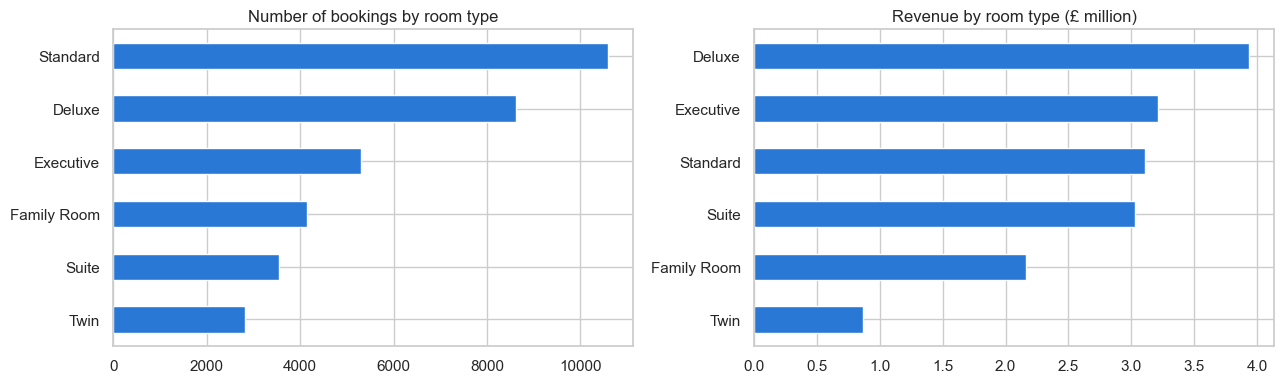

Total revenue: £16.31 million


In [52]:
room = bookings.groupby("room_type").agg(bookings=("booking_id", "count"),
                                         revenue=("total_amount", "sum"))
room["booking_share_%"] = (room["bookings"] / room["bookings"].sum() * 100).round(1)
room["revenue_share_%"] = (room["revenue"] / room["revenue"].sum() * 100).round(1)
room["avg_booking_value"] = (room["revenue"] / room["bookings"]).round(0)
room = room.sort_values("revenue", ascending=False)
display(room)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
room["bookings"].sort_values().plot.barh(ax=ax[0], color=BLUE)
ax[0].set_title("Number of bookings by room type")
(room["revenue"] / 1e6).sort_values().plot.barh(ax=ax[1], color=BLUE)
ax[1].set_title("Revenue by room type (£ million)")
for a in ax: a.set_ylabel("")
plt.tight_layout(); plt.show()
print(f"Total revenue: £{bookings['total_amount'].sum() / 1e6:.2f} million")

<<INSIGHT:rooms>>

**What this code does:**
- Does the same for the booking channels (Direct Website, Booking.com, Expedia, and so on).

,bookings,revenue,revenue_share_%,avg_booking_value
booking_channel,,,,
Direct Website,8688,4051385.20,24.8,466.0
Booking.com,7808,3654237.93,22.4,468.0
Expedia,5273,2452361.55,15.0,465.0
Travel Agent,3529,1618571.44,9.9,459.0
Corporate Portal,3411,1611396.00,9.9,472.0
Airbnb,3416,1604609.36,9.8,470.0
Walk-in,2875,1319438.23,8.1,459.0


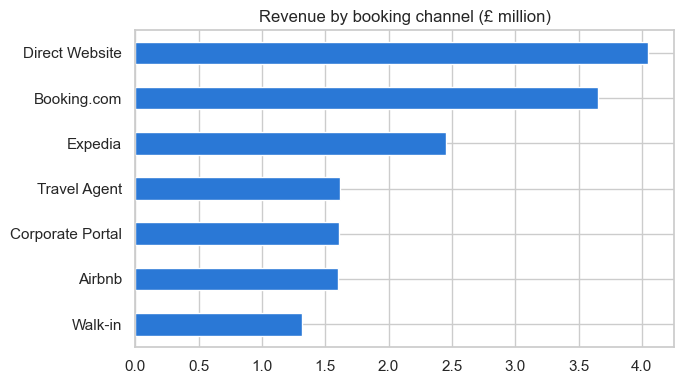

In [53]:
channel = bookings.groupby("booking_channel").agg(bookings=("booking_id", "count"),
                                                  revenue=("total_amount", "sum"))
channel["revenue_share_%"] = (channel["revenue"] / channel["revenue"].sum() * 100).round(1)
channel["avg_booking_value"] = (channel["revenue"] / channel["bookings"]).round(0)
channel = channel.sort_values("revenue", ascending=False)
display(channel)

fig, ax = plt.subplots(figsize=(7, 4))
(channel["revenue"] / 1e6).sort_values().plot.barh(ax=ax, color=BLUE)
ax.set_title("Revenue by booking channel (£ million)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

<<INSIGHT:channels>>

**What this code does:**
- Counts how many bookings there are for each stay length (number of nights) and prints the summary statistics.

count    35000.00
mean         2.95
std          1.50
min          1.00
25%          2.00
50%          3.00
75%          4.00
max          7.00
Name: stay_duration, dtype: float64


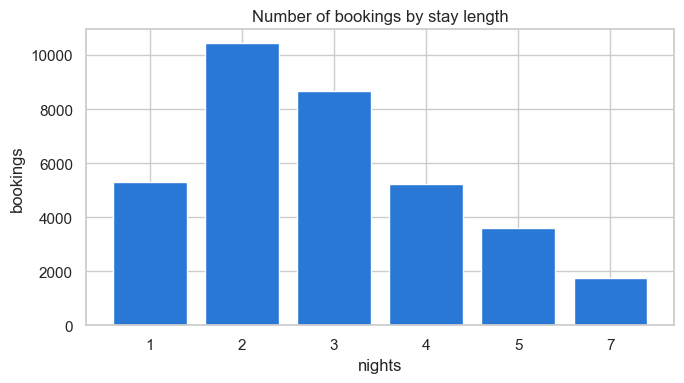

,bookings
stay_duration,
1,5299
2,10425
3,8679
4,5243
5,3614
7,1740


In [54]:
stay = bookings["stay_duration"].value_counts().sort_index()
print(bookings["stay_duration"].describe().round(2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(stay.index.astype(str), stay.values, color=BLUE)
ax.set_title("Number of bookings by stay length"); ax.set_xlabel("nights"); ax.set_ylabel("bookings")
plt.tight_layout(); plt.show()
display(stay.rename("bookings").to_frame())

<<INSIGHT:stay>>

### 2.6 Can every review be linked to its booking, guest and hotel?

**What this code does:**
- Checks that every `booking_id`, `guest_id` and `hotel_id` in the reviews table exists in the other tables.
- Checks that each booking has only one review.
- A count of 0 problems means the tables join perfectly.

In [55]:
checks = pd.DataFrame({
    "check": ["review's booking exists in bookings",
              "review's guest exists in guests",
              "review's hotel exists in hotels",
              "only one review per booking"],
    "problems found": [(~reviews["booking_id"].isin(bookings["booking_id"])).sum(),
                       (~reviews["guest_id"].isin(guests["guest_id"])).sum(),
                       (~reviews["hotel_id"].isin(hotels["hotel_id"])).sum(),
                       reviews["booking_id"].duplicated().sum()]})
checks["result"] = np.where(checks["problems found"] == 0, "PASS", "FAIL")
checks

,check,problems found,result
0,review's booking exists in bookings,0,PASS
1,review's guest exists in guests,0,PASS
2,review's hotel exists in hotels,0,PASS
3,only one review per booking,0,PASS


### 2.7 Join the four tables into one

**What this code does:**
- Starts from the reviews table and adds the booking details (matched on `booking_id`), then the guest details (`guest_id`), then the hotel details (`hotel_id`).
- `guest_id` and `hotel_id` are dropped from bookings before the first join, because the reviews table already has them (otherwise they would appear twice).
- Checks that the result still has exactly one row per review.

In [56]:
data = (reviews
        .merge(bookings.drop(columns=["guest_id", "hotel_id"]), on="booking_id", how="left")
        .merge(guests, on="guest_id", how="left")
        .merge(hotels, on="hotel_id", how="left"))

print("Combined table:", data.shape[0], "rows ×", data.shape[1], "columns")
print("Rows gained or lost in the join:", len(data) - len(reviews))
data.head(3)

Combined table: 35000 rows × 22 columns
Rows gained or lost in the join: 0


,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,room_type,booking_channel,...,total_amount,stay_duration,customer_type,loyalty_status,country,previous_stays,hotel_name,location,star_rating,total_rooms
0,1,1,6699,18,"The overall price was fair for what we paid. Might consider it again, might not.",3.2,2025-06-02,neutral,Suite,Direct Website,...,296.44,1,Leisure,None,France,4,The Aberdeen Grand,Aberdeen,4,118
1,2,2,11380,23,The room was nothing out of the ordinary for what we paid. The overall price exceeded our expect...,4.0,2025-01-22,positive,Deluxe,Corporate Portal,...,483.56,4,Business,Gold,Germany,4,Nottingham Park Hotel,Nottingham,4,95
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recommend it to o...",1.9,2025-03-13,negative,Executive,Travel Agent,...,415.59,2,Business,None,Ireland,4,The London Boutique,London,4,231


<<INSIGHT:join>>

---
# Data Cleaning and Preparation

**Goal:** make the combined table reliable before exploring it, and prepare clean review text for the NLP phases. Every change is recorded in a **cleaning log**, so the steps can be explained and repeated.

**What this code does:**
- Makes a working copy of the combined table, so the raw data stays untouched.
- Creates an empty cleaning log and a small helper function `log()` that adds one line to it.

In [57]:
df = data.copy()
cleaning_log = []

def log(step, rows_affected, action):
    cleaning_log.append({"step": step, "rows affected": int(rows_affected), "action": action})

### 3.1 Missing values

**What this code does:**
- Counts the missing values in every column.
- `loyalty_status` is the only column with gaps. Those guests are simply not enrolled in the loyalty programme, so the gap is filled with **"No membership"** instead of deleting rows.

In [58]:
missing = df.isna().sum()
print("Missing values per column (only columns with gaps):")
print(missing[missing > 0])

n_missing = df["loyalty_status"].isna().sum()
df["loyalty_status"] = df["loyalty_status"].fillna("No membership")
log("Missing loyalty_status", n_missing, "Filled with 'No membership' (guest not enrolled)")

print("\nMissing values left:", df.isna().sum().sum())
print(df["loyalty_status"].value_counts())

Missing values per column (only columns with gaps):
loyalty_status    17615
dtype: int64

Missing values left: 0
loyalty_status
No membership    17615
Silver            8605
Gold              5857
Platinum          2923
Name: count, dtype: int64


<<INSIGHT:missing>>

### 3.2 Duplicates

**What this code does:**
- Looks for three kinds of duplicates: identical rows, repeated `review_id`, and different reviews with exactly the same text.
- Among the reviews with the same text, it finds those that carry **different sentiment labels** (for example the same sentence labelled *negative* once and *neutral* another time).
- Shows a few examples.

In [59]:
print("Identical rows:", df.duplicated().sum())
print("Repeated review_id:", df["review_id"].duplicated().sum())

same_text = df["review_text"].duplicated(keep=False)
print("Reviews whose text also appears in another review:", same_text.sum())

labels_per_text = df[same_text].groupby("review_text")["sentiment_label"].nunique()
conflict_texts = labels_per_text[labels_per_text > 1].index
df["conflicting_label"] = df["review_text"].isin(conflict_texts)
print("Of those, texts with conflicting labels:", len(conflict_texts),
      "texts →", df["conflicting_label"].sum(), "reviews")

df.loc[df["conflicting_label"], ["review_id", "review_text", "rating_score", "sentiment_label"]] \
  .sort_values("review_text").head(6)

Identical rows: 0
Repeated review_id: 0
Reviews whose text also appears in another review: 829
Of those, texts with conflicting labels: 76 texts → 196 reviews


,review_id,review_text,rating_score,sentiment_label
4307,4295,I'd describe getting around from the hotel as fine — nothing was within walking distance but tra...,2.2,negative
27072,27066,I'd describe getting around from the hotel as fine — nothing was within walking distance but tra...,3.3,negative
22282,22266,I'd describe getting around from the hotel as fine — nothing was within walking distance but tra...,3.2,neutral
12424,12409,I'd describe getting around from the hotel as fine — nothing was within walking distance but tra...,2.6,neutral
17676,17660,I'd describe getting around from the hotel as not the most convenient but manageable — it was a ...,4.7,positive
8345,8330,I'd describe getting around from the hotel as not the most convenient but manageable — it was a ...,3.9,positive


<<INSIGHT:duplicates>>

**Decision:**
- Reviews with the same text come from different guests, bookings and hotels, so they are **kept** for the business analysis.
- For the sentiment model (later phases), each text is kept **only once**, so the same sentence cannot appear in both the training and the test data.
- The 196 reviews whose identical text carries different labels are **removed from the modelling data**, because a model cannot learn from contradictory examples.

In [60]:
log("Same text in several reviews", same_text.sum(), "Kept for analysis; kept once for modelling")
log("Same text, different labels", df["conflicting_label"].sum(), "Removed from the modelling data")

### 3.3 Data types

**What this code does:**
- The date columns arrive as plain text. `pd.to_datetime` converts them into real dates, so we can calculate time differences and group by month.
- Adds `days_to_review`: how many days after check-out the review was written.

In [61]:
print("Before:", df[["review_date", "check_in_date", "check_out_date"]].dtypes.to_dict())
for col in ["review_date", "check_in_date", "check_out_date"]:
    df[col] = pd.to_datetime(df[col])
print("After: ", df[["review_date", "check_in_date", "check_out_date"]].dtypes.to_dict())

df["days_to_review"] = (df["review_date"] - df["check_out_date"]).dt.days
log("Date columns", len(df), "Converted from text to dates")

Before: {'review_date': dtype('O'), 'check_in_date': dtype('O'), 'check_out_date': dtype('O')}
After:  {'review_date': dtype('<M8[ns]'), 'check_in_date': dtype('<M8[ns]'), 'check_out_date': dtype('<M8[ns]')}


### 3.4 Validity checks

**What this code does:**
- Checks business rules the data must respect: ratings between 1 and 5, no empty review, a review written after check-out, a stay length matching the dates, and a positive amount paid.
- Counts the rows breaking each rule (0 = rule respected everywhere).

In [62]:
validity = pd.DataFrame({
    "rule": ["rating between 1 and 5",
             "review text not empty",
             "review written after check-out",
             "stay_duration = check-out minus check-in",
             "amount paid above 0"],
    "rows breaking the rule": [
        (~df["rating_score"].between(1, 5)).sum(),
        (df["review_text"].str.strip() == "").sum(),
        (df["days_to_review"] < 0).sum(),
        ((df["check_out_date"] - df["check_in_date"]).dt.days != df["stay_duration"]).sum(),
        (df["total_amount"] <= 0).sum()]})
validity["result"] = np.where(validity["rows breaking the rule"] == 0, "PASS", "FIX")
display(validity)
print("Days between check-out and review: from", df["days_to_review"].min(), "to", df["days_to_review"].max())

,rule,rows breaking the rule,result
0,rating between 1 and 5,0,PASS
1,review text not empty,0,PASS
2,review written after check-out,0,PASS
3,stay_duration = check-out minus check-in,0,PASS
4,amount paid above 0,0,PASS


Days between check-out and review: from 0 to 14


<<INSIGHT:validity>>

### 3.5 Inconsistent values

**What this code does:**
- Looks for hotels that share the same name.
- Two different hotels (#9 and #14) are both called *Edinburgh Riverside Hotel*. A new column `hotel_label` adds the hotel number to their names, so they are never merged in hotel comparisons.
- Removes stray spaces in the text categories and counts the distinct values of each, to check there are no spelling variants.

In [63]:
same_name = hotels[hotels["hotel_name"].duplicated(keep=False)]
display(same_name)

df["hotel_label"] = df["hotel_name"]
is_shared = df["hotel_name"].isin(same_name["hotel_name"])
df.loc[is_shared, "hotel_label"] = df["hotel_name"] + " (#" + df["hotel_id"].astype(str) + ")"
log("Two hotels with the same name", is_shared.sum(), "Hotel number added to the name")

category_cols = ["room_type", "booking_channel", "customer_type", "loyalty_status",
                 "country", "location", "sentiment_label"]
for col in category_cols:
    df[col] = df[col].str.strip()
print("Distinct values per category:", {col: df[col].nunique() for col in category_cols})

,hotel_id,hotel_name,location,star_rating,total_rooms
8,9,Edinburgh Riverside Hotel,Edinburgh,3,71
13,14,Edinburgh Riverside Hotel,Edinburgh,3,215


Distinct values per category: {'room_type': 6, 'booking_channel': 7, 'customer_type': 5, 'loyalty_status': 4, 'country': 15, 'location': 14, 'sentiment_label': 3}


<<INSIGHT:inconsistent>>

### 3.6 Clean the review text

Computers compare text character by character, so *"Wouldn't"*, *"wouldn't"* and *"would not"* would look like three different things. Cleaning puts every review into the same simple form. Three choices matter:
- **Negation is kept.** *"not clean"* and *"clean"* mean opposite things, so *not*, *no* and *never* are never removed.
- **Contractions are expanded** (*"wouldn't"* → *"would not"*), so negation always appears as the word *not*.
- **Special characters are replaced** (*"—"* → *"-"*, *"é"* → *"e"*), so the same word is always written the same way.

**What this code does:**
- Defines a function `clean_review()` that: replaces special characters, lower-cases, expands contractions, removes punctuation and numbers, and removes extra spaces.
- Shows two reviews before and after cleaning.
- Applies the function to all 35,000 reviews and stores the result in a new column `text_clean` (the original text is kept).

In [64]:
import unicodedata

CONTRACTIONS = {"won't": "will not", "can't": "can not", "n't": " not", "'re": " are",
                "'d": " would", "'ll": " will", "'ve": " have", "'m": " am"}

def clean_review(text):
    text = text.replace("—", "-").replace("–", "-").replace("’", "'")
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()   # é -> e
    text = text.lower()
    for short, full in CONTRACTIONS.items():
        text = text.replace(short, full)
    text = re.sub(r"[^a-z\s]", " ", text)        # keep letters and spaces only
    text = re.sub(r"\s+", " ", text).strip()      # remove extra spaces
    return text

for i in [1, 2]:
    print("BEFORE:", df.loc[i, "review_text"])
    print("AFTER :", clean_review(df.loc[i, "review_text"]))
    print()

df["text_clean"] = df["review_text"].apply(clean_review)
n_special = df["review_text"].str.contains(r"[^\x00-\x7F]").sum()
log("Special characters (—, é)", n_special, "Replaced by plain equivalents")
log("Review text", len(df), "Lower-cased, contractions expanded, punctuation removed")
print("Words per cleaned review: average", round(df["text_clean"].str.split().str.len().mean(), 1))

BEFORE: The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations — a great deal, and the quality easily matched the price.
AFTER : the room was nothing out of the ordinary for what we paid the overall price exceeded our expectations a great deal and the quality easily matched the price

BEFORE: Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recommend it to others.
AFTER : unfortunately the pool was outdated it clearly needed some upkeep would not recommend it to others

Words per cleaned review: average 29.5


<<INSIGHT:text>>

### 3.7 Flag labels that disagree with the rating

**What this code does:**
- Converts each rating into the sentiment it suggests: below 2.5 = negative, 2.5 to 3.5 = neutral, 3.5 and above = positive.
- Flags the reviews whose sentiment label disagrees with that rating band (`label_rating_conflict`). They are not deleted; the flag is used later to understand the model's mistakes.

In [65]:
def rating_to_sentiment(rating):
    if rating < 2.5:
        return "negative"
    elif rating < 3.5:
        return "neutral"
    return "positive"

df["rating_sentiment"] = df["rating_score"].apply(rating_to_sentiment)
df["label_rating_conflict"] = df["sentiment_label"] != df["rating_sentiment"]
print("Reviews whose label disagrees with the rating:", df["label_rating_conflict"].sum(),
      f"({df['label_rating_conflict'].mean():.2%})")
log("Label disagrees with rating", df["label_rating_conflict"].sum(), "Flagged (label_rating_conflict), not deleted")
pd.crosstab(df["sentiment_label"], df["rating_sentiment"]).reindex(index=SENT_ORDER, columns=SENT_ORDER)

Reviews whose label disagrees with the rating: 1871 (5.35%)


rating_sentiment,negative,neutral,positive
sentiment_label,,,
negative,9320,543,0
neutral,342,12625,388
positive,0,598,11184


<<INSIGHT:conflict>>

### 3.8 Validate the cleaned data with Great Expectations

**What this code does:**
- Great Expectations is a data-validation library. Each **expectation** is a rule the data must satisfy; the library tests it and reports how many rows break it.
- We test seven rules on the cleaned table: unique review IDs, no missing text or loyalty status, ratings between 1 and 5, only the three sentiment labels, reviews written 0 days or more after check-out, and still 35,000 rows.

In [66]:
%pip install great-expectations
import great_expectations as gx

context = gx.get_context(mode="ephemeral")
batch = (context.data_sources.add_pandas("montra")
         .add_dataframe_asset(name="reviews_clean")
         .add_batch_definition_whole_dataframe("all rows")
         .get_batch(batch_parameters={"dataframe": df}))

rules = [
    gx.expectations.ExpectColumnValuesToBeUnique(column="review_id"),
    gx.expectations.ExpectColumnValuesToNotBeNull(column="review_text"),
    gx.expectations.ExpectColumnValuesToNotBeNull(column="loyalty_status"),
    gx.expectations.ExpectColumnValuesToBeBetween(column="rating_score", min_value=1, max_value=5),
    gx.expectations.ExpectColumnValuesToBeInSet(column="sentiment_label", value_set=SENT_ORDER),
    gx.expectations.ExpectColumnValuesToBeBetween(column="days_to_review", min_value=0),
    gx.expectations.ExpectTableRowCountToEqual(value=len(reviews)),
]
results = []
import contextlib, io
for rule in rules:
    with contextlib.redirect_stderr(io.StringIO()):     # hides the library's progress bars
        outcome = batch.validate(rule)
    results.append({"rule": type(rule).__name__, "column": getattr(rule, "column", "whole table"),
                    "passed": outcome.success})
results = pd.DataFrame(results)
display(results)
print(results["passed"].sum(), "of", len(results), "rules passed")

Note: you may need to restart the kernel to use updated packages.


Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/8 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/8 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/1 [00:00<?, ?it/s]

,rule,column,passed
0,ExpectColumnValuesToBeUnique,review_id,True
1,ExpectColumnValuesToNotBeNull,review_text,True
2,ExpectColumnValuesToNotBeNull,loyalty_status,True
3,ExpectColumnValuesToBeBetween,rating_score,True
4,ExpectColumnValuesToBeInSet,sentiment_label,True
5,ExpectColumnValuesToBeBetween,days_to_review,True
6,ExpectTableRowCountToEqual,whole table,True


7 of 7 rules passed


<<INSIGHT:gx>>

### 3.9 Save the cleaned datasets

**What this code does:**
- Saves two files in `data/processed`:
- **`reviews_clean.csv`**: all 35,000 reviews with their booking, guest and hotel details, for the business analysis.
- **`nlp_corpus.csv`**: the data for the sentiment model, with each review text kept once and the contradictory-label texts removed.
- Displays the full cleaning log.

In [67]:
analysis_cols = ["review_id", "booking_id", "guest_id", "hotel_id", "hotel_label", "location", "star_rating",
                 "total_rooms", "review_date", "review_text", "text_clean", "rating_score", "sentiment_label",
                 "label_rating_conflict", "room_type", "booking_channel", "check_in_date", "stay_duration",
                 "total_amount", "customer_type", "loyalty_status", "country", "previous_stays", "days_to_review"]
reviews_clean = df[analysis_cols]
reviews_clean.to_csv(PROC_DIR / "reviews_clean.csv", index=False)

nlp_corpus = (df[~df["conflicting_label"]]
              .drop_duplicates("review_text")
              [["review_id", "review_text", "text_clean", "rating_score", "sentiment_label", "label_rating_conflict"]])
nlp_corpus.to_csv(PROC_DIR / "nlp_corpus.csv", index=False)
log("Modelling data", len(df) - len(nlp_corpus), "Rows removed (repeated texts and contradictory labels)")

print("reviews_clean.csv:", reviews_clean.shape)
print("nlp_corpus.csv   :", nlp_corpus.shape)
pd.DataFrame(cleaning_log)

reviews_clean.csv: (35000, 24)
nlp_corpus.csv   : (34460, 6)


,step,rows affected,action
0,Missing loyalty_status,17615,Filled with 'No membership' (guest not enrolled)
1,Same text in several reviews,829,Kept for analysis; kept once for modelling
2,"Same text, different labels",196,Removed from the modelling data
3,Date columns,35000,Converted from text to dates
4,Two hotels with the same name,2909,Hotel number added to the name
5,"Special characters (—, é)",12398,Replaced by plain equivalents
6,Review text,35000,"Lower-cased, contractions expanded, punctuation removed"
7,Label disagrees with rating,1871,"Flagged (label_rating_conflict), not deleted"
8,Modelling data,540,Rows removed (repeated texts and contradictory labels)


<<INSIGHT:phase3>>

---
# Phase 4 — Exploratory Data Analysis (EDA)

**Goal:** understand the cleaned data before modelling: how sentiment and ratings are distributed, how they change over time, what the review text looks like, and whether hotels, guests or bookings make a difference.

All EDA below uses `reviews_clean` (35,000 reviews), the cleaned table from Phase 3.

**What this code does:**
- Adds a few helper columns for the analysis: the review month, the number of words in each review, and a 0/1 column `is_negative` (its average gives the share of negative reviews).
- Prints the size of the dataset.

In [68]:
eda = reviews_clean.copy()
eda["month"] = eda["review_date"].dt.to_period("M").dt.to_timestamp()
eda["word_count"] = eda["review_text"].str.split().str.len()
eda["is_negative"] = (eda["sentiment_label"] == "negative").astype(int)

print(f"{len(eda):,} reviews | {eda['hotel_id'].nunique()} hotels in {eda['location'].nunique()} cities | "
      f"{eda['guest_id'].nunique():,} guests | {eda['review_date'].min():%d %b %Y} to {eda['review_date'].max():%d %b %Y}")

35,000 reviews | 25 hotels in 14 cities | 11,377 guests | 02 Jan 2025 to 30 Jun 2026


### 4.1 How is sentiment distributed?

**What this code does:**
- Counts the reviews in each sentiment class and shows them as a bar chart with percentages.

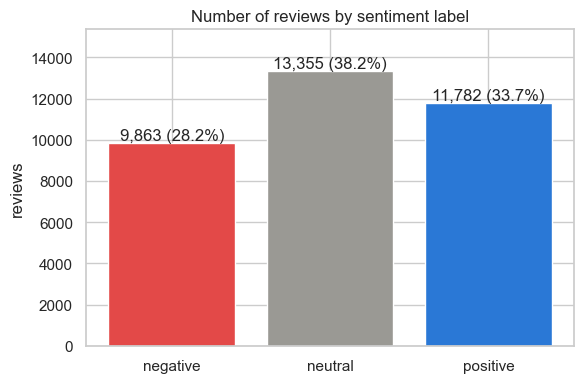

In [69]:
counts = eda["sentiment_label"].value_counts().reindex(SENT_ORDER)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index, counts.values, color=[SENT_COLORS[s] for s in counts.index])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,} ({v / len(eda):.1%})", ha="center", va="bottom")
ax.set_title("Number of reviews by sentiment label"); ax.set_ylabel("reviews")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); plt.show()

<<INSIGHT:eda_labels>>

### 4.2 How do ratings relate to the sentiment labels?

**What this code does:**
- Draws the distribution of rating scores separately for negative, neutral and positive reviews.
- Prints the average and the minimum and maximum rating of each sentiment class.

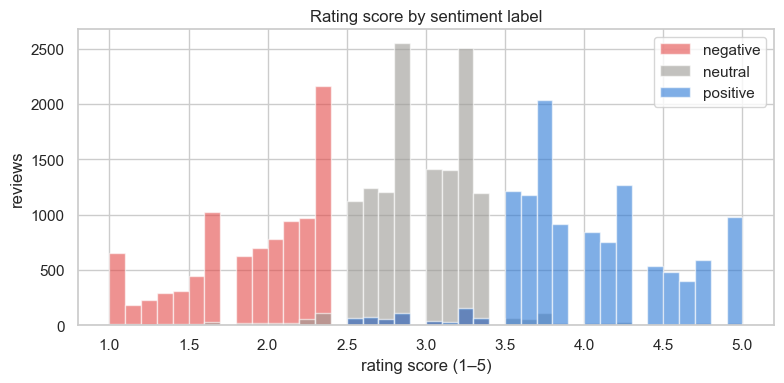

,mean,min,max
sentiment_label,,,
negative,1.94,1.0,3.4
neutral,2.96,1.0,5.0
positive,4.01,2.5,5.0


In [70]:
fig, ax = plt.subplots(figsize=(8, 4))
for s in SENT_ORDER:
    ax.hist(eda.loc[eda["sentiment_label"] == s, "rating_score"], bins=40, range=(1, 5),
            color=SENT_COLORS[s], alpha=0.6, label=s)
ax.set_title("Rating score by sentiment label"); ax.set_xlabel("rating score (1–5)"); ax.set_ylabel("reviews")
ax.legend()
plt.tight_layout(); plt.show()
eda.groupby("sentiment_label")["rating_score"].agg(["mean", "min", "max"]).round(2).reindex(SENT_ORDER)

<<INSIGHT:eda_ratings>>

### 4.3 Is anything changing over time?

**What this code does:**
- Counts reviews per month and calculates the average rating and the share of negative reviews per month.
- Draws them as two separate charts (volume, then rating and negative share), so each chart has a single scale.

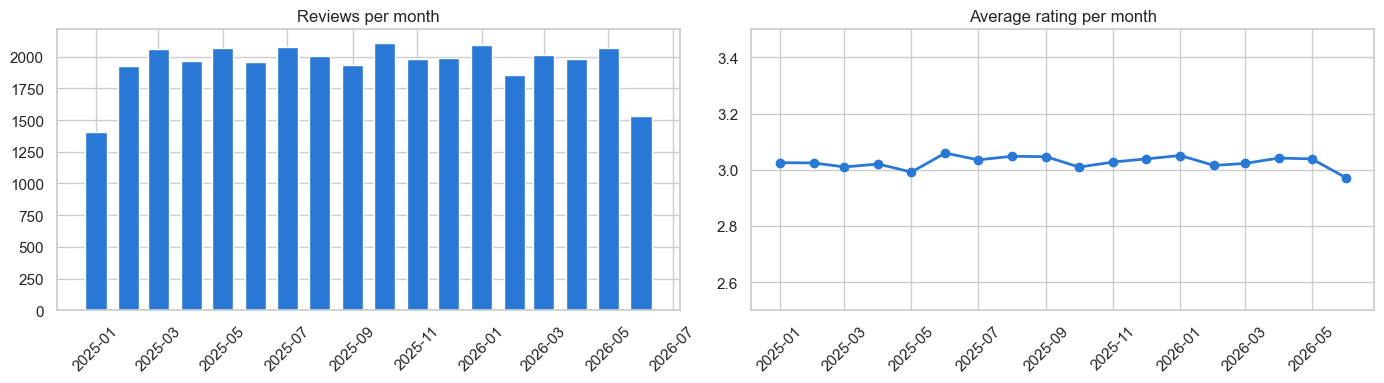

Reviews per month: 1406 to 2109
Average rating per month: 2.97 to 3.06
Negative share per month: 26.0% to 30.3%


In [71]:
monthly = eda.groupby("month").agg(reviews=("review_id", "count"),
                                   avg_rating=("rating_score", "mean"),
                                   negative_share=("is_negative", "mean"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(monthly.index, monthly["reviews"], width=20, color=BLUE)
ax[0].set_title("Reviews per month")
ax[1].plot(monthly.index, monthly["avg_rating"], marker="o", color=BLUE, lw=2)
ax[1].set_ylim(2.5, 3.5); ax[1].set_title("Average rating per month")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print("Reviews per month:", monthly["reviews"].min(), "to", monthly["reviews"].max())
print("Average rating per month: %.2f to %.2f" % (monthly["avg_rating"].min(), monthly["avg_rating"].max()))
print("Negative share per month: %.1f%% to %.1f%%" % (monthly["negative_share"].min() * 100, monthly["negative_share"].max() * 100))

<<INSIGHT:eda_time>>

### 4.4 What does the review text look like?

**What this code does:**
- Draws the distribution of review length (number of words), overall and by sentiment.
- Calculates the correlation between review length and rating (close to 0 = no relationship).

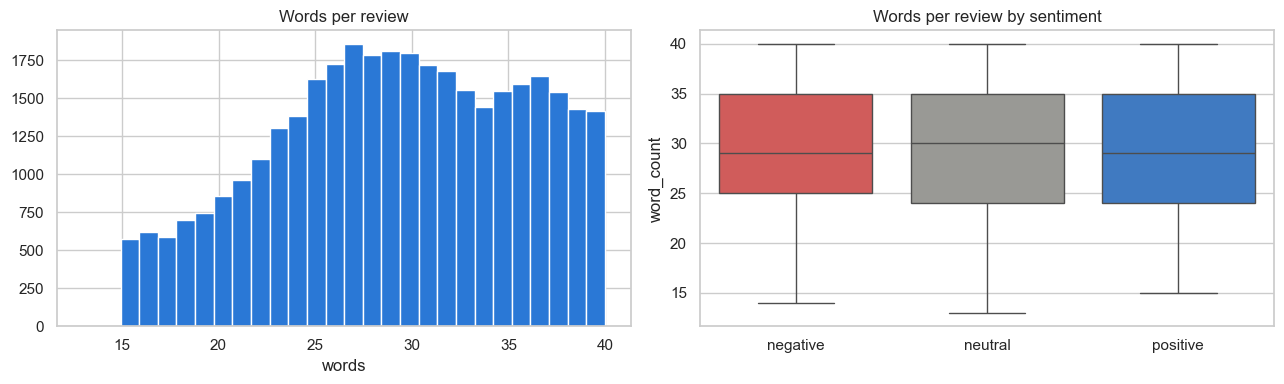

count    35000.0
mean        29.2
std          6.6
min         13.0
25%         24.0
50%         29.0
75%         35.0
max         40.0
Name: word_count, dtype: float64
Correlation between length and rating: 0.002


In [72]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(eda["word_count"], bins=28, color=BLUE)
ax[0].set_title("Words per review"); ax[0].set_xlabel("words")
sns.boxplot(data=eda, x="sentiment_label", y="word_count", order=SENT_ORDER, palette=SENT_COLORS, ax=ax[1])
ax[1].set_title("Words per review by sentiment"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()
print(eda["word_count"].describe().round(1))
print("Correlation between length and rating: %.3f" % eda["word_count"].corr(eda["rating_score"]))

<<INSIGHT:eda_length>>

### 4.5 Which words are typical of each sentiment?

**What this code does:**
- Counts how often each word appears in negative, neutral and positive reviews (common words such as *the*, *and*, *was* are ignored).
- For each sentiment, keeps the words that appear more often in that class than in the other two classes put together, and lists the most frequent ones.
- Measures how often negation (*not, no, never*) and hedging words (*fine, acceptable, about what we expected*) appear in each class.

In [73]:
from collections import Counter

STOPWORDS = {"the", "a", "an", "and", "or", "was", "were", "is", "it", "to", "of", "in", "for", "we", "our",
             "with", "at", "on", "that", "this", "as", "be", "had", "by", "from", "they", "there", "very", "what",
             "i", "which", "would", "could", "here", "well", "got", "more", "less", "about", "lot", "it"}
word_counts = {}
for s in SENT_ORDER:
    words = " ".join(eda.loc[eda["sentiment_label"] == s, "text_clean"]).split()
    word_counts[s] = Counter(w for w in words if w not in STOPWORDS)

for s in SENT_ORDER:
    others = sum((word_counts[o] for o in SENT_ORDER if o != s), Counter())
    typical = [w for w, n in word_counts[s].most_common(400) if n > others.get(w, 0)]
    print(f"{s:<9}:", ", ".join(typical[:12]))

patterns = {"negation (not / no / never)": r"\b(?:not|no|never)\b",
            "hedging (fine / acceptable / about what we expected)": r"\b(?:fine|okay|acceptable|nothing special|about what we expected|standard)\b"}
markers = pd.DataFrame({name: eda["text_clean"].str.contains(p) for name, p in patterns.items()})
(markers.groupby(eda["sentiment_label"]).mean().reindex(SENT_ORDER).T * 100).round(1).add_suffix(" %")

negative : not, disappointed, left, sadly, turned, really, affected, desired, unfortunately, experience, did, high
neutral  : nothing, overall, paid, expected, fine, describe, acceptable, but, if, fairly, ordinary, unremarkable
positive : genuinely, honestly, impressed, stood, exceeded, expectations, great, trip, again, worth, excellent, asked


sentiment_label,negative %,neutral %,positive %
negation (not / no / never),47.9,18.5,12.4
hedging (fine / acceptable / about what we expected),19.5,81.9,18.6


<<INSIGHT:eda_words>>

### 4.6 Do hotels differ?

**What this code does:**
- Calculates, for each hotel, the number of reviews, the average rating and the share of negative reviews.
- Draws the average rating of each hotel, coloured by star rating, and prints the average rating by star rating and by city.

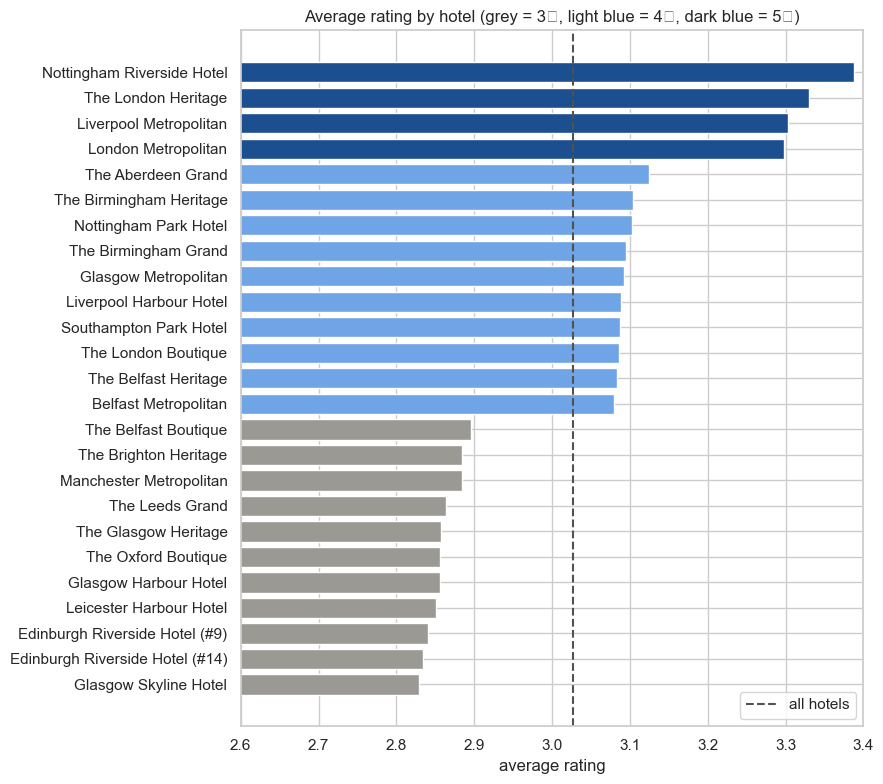

Best minus worst hotel: 0.56 rating points


,count,mean
star_rating,,
3,15450,2.86
4,14084,3.09
5,5466,3.33


,hotels,avg_rating,negative_share
location,,,
Nottingham,2,3.246,0.209
London,3,3.236,0.213
Liverpool,2,3.192,0.229
Aberdeen,1,3.125,0.246
Birmingham,2,3.099,0.253
Southampton,1,3.088,0.260
Belfast,3,3.020,0.284
Glasgow,4,2.910,0.321
Brighton,1,2.885,0.332


In [74]:
hotel = (eda.groupby(["hotel_label", "location", "star_rating"])
         .agg(reviews=("review_id", "count"), avg_rating=("rating_score", "mean"), negative_share=("is_negative", "mean"))
         .reset_index().sort_values("avg_rating"))

star_colors = {3: "#9a9994", 4: "#6fa4e6", 5: "#1b4f8f"}
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(hotel["hotel_label"], hotel["avg_rating"], color=hotel["star_rating"].map(star_colors))
ax.axvline(eda["rating_score"].mean(), ls="--", color="#52514e", label="all hotels")
ax.set_xlim(2.6, 3.4); ax.set_xlabel("average rating")
ax.set_title("Average rating by hotel (grey = 3★, light blue = 4★, dark blue = 5★)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

print("Best minus worst hotel: %.2f rating points" % (hotel["avg_rating"].max() - hotel["avg_rating"].min()))
display(eda.groupby("star_rating")["rating_score"].agg(["count", "mean"]).round(2))
eda.groupby("location").agg(hotels=("hotel_id", "nunique"), avg_rating=("rating_score", "mean"),
                            negative_share=("is_negative", "mean")).sort_values("avg_rating", ascending=False).round(3)

<<INSIGHT:eda_hotels>>

### 4.7 Do guest characteristics matter?

**What this code does:**
- Defines a small function `compare()` that gives, for each group of a column, the number of reviews, the average rating and the negative share.
- Applies it to customer type and loyalty status, and draws the negative share for each group.

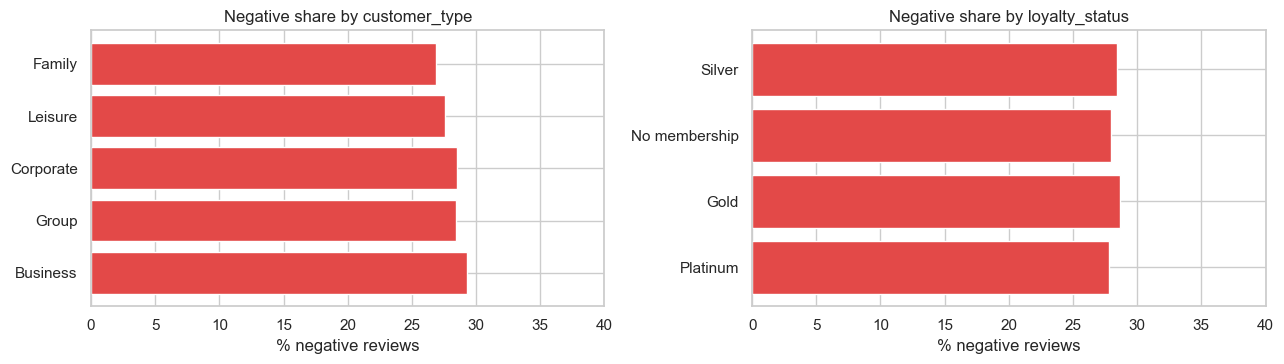

,reviews,avg_rating,negative_share
customer_type,,,
Business,8404,3.000,0.293
Group,3564,3.006,0.284
Corporate,5517,3.024,0.285
Leisure,14000,3.042,0.276
Family,3515,3.061,0.269


,reviews,avg_rating,negative_share
loyalty_status,,,
Platinum,2923,3.010,0.278
Gold,5857,3.022,0.287
No membership,17615,3.027,0.280
Silver,8605,3.037,0.284


In [75]:
def compare(column):
    return (eda.groupby(column).agg(reviews=("review_id", "count"), avg_rating=("rating_score", "mean"),
                                    negative_share=("is_negative", "mean"))
            .sort_values("avg_rating").round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, col in zip(ax, ["customer_type", "loyalty_status"]):
    t = compare(col)
    a.barh(t.index, t["negative_share"] * 100, color="#e34948")
    a.set_xlim(0, 40); a.set_xlabel("% negative reviews"); a.set_title(f"Negative share by {col}")
plt.tight_layout(); plt.show()
display(compare("customer_type"))
display(compare("loyalty_status"))

<<INSIGHT:eda_guests>>

### 4.8 Do booking characteristics matter?

**What this code does:**
- Uses the same `compare()` function for room type, booking channel and stay length.
- Calculates the correlation between the rating and the numeric variables (amount paid, stay length, previous stays, star rating, hotel size).

In [76]:
display(compare("room_type"))
display(compare("booking_channel"))
display(compare("stay_duration"))

for col in ["total_amount", "stay_duration", "previous_stays", "star_rating", "total_rooms"]:
    print(f"Correlation of rating with {col:<15}: {eda['rating_score'].corr(eda[col]):+.3f}")

,reviews,avg_rating,negative_share
room_type,,,
Suite,3544,3.007,0.282
Family Room,4137,3.023,0.289
Standard,10596,3.025,0.281
Executive,5293,3.031,0.282
Twin,2811,3.032,0.277
Deluxe,8619,3.037,0.281


,reviews,avg_rating,negative_share
booking_channel,,,
Travel Agent,3529,3.013,0.292
Walk-in,2875,3.021,0.293
Direct Website,8688,3.022,0.279
Airbnb,3416,3.029,0.285
Corporate Portal,3411,3.034,0.282
Booking.com,7808,3.034,0.280
Expedia,5273,3.036,0.274


,reviews,avg_rating,negative_share
stay_duration,,,
1,5299,3.020,0.282
3,8679,3.022,0.285
2,10425,3.024,0.284
5,3614,3.034,0.281
4,5243,3.039,0.274
7,1740,3.054,0.275


Correlation of rating with total_amount   : +0.003
Correlation of rating with stay_duration  : +0.008
Correlation of rating with previous_stays : +0.007
Correlation of rating with star_rating    : +0.182
Correlation of rating with total_rooms    : +0.074


<<INSIGHT:eda_bookings>>

### 4.9 Correlation between the numeric variables

**What this code does:**
- Draws a heatmap of the correlations between all numeric columns. Values close to +1 or −1 mean a strong relationship; values close to 0 mean none.

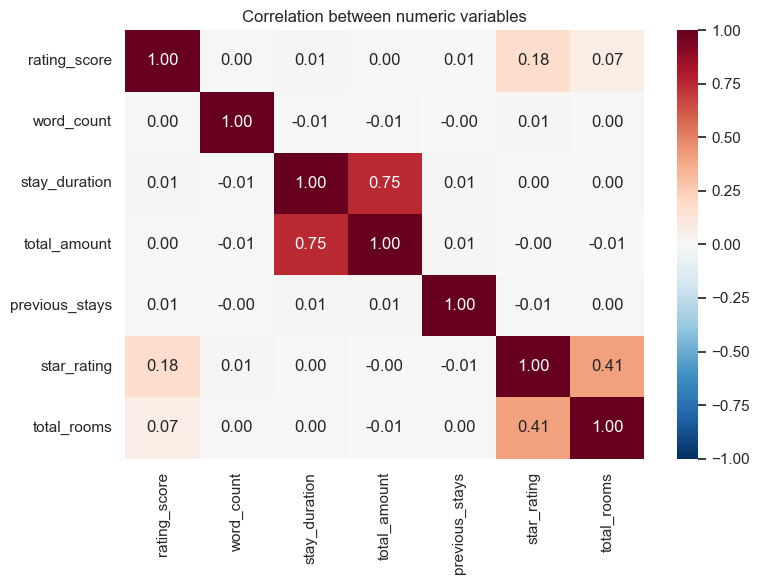

In [77]:
numeric = eda[["rating_score", "word_count", "stay_duration", "total_amount", "previous_stays", "star_rating", "total_rooms"]]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between numeric variables")
plt.tight_layout(); plt.show()

<<INSIGHT:eda_corr>>

<<INSIGHT:summary>>